# 📊 Twitter Sentiment Analysis with Explainable AI (XAI)
## End-to-End NLP Pipeline, Token Attribution Engine, and Interactive Dashboard

---

### Executive Summary
This project provides a complete Natural Language Processing (NLP) system designed to classify social media sentiment and provide mathematical interpretability for individual model decisions. Built on scikit-learn, NLTK, and Streamlit, the system implements:
1. **Regularized Linear Sentiment Classifier:** Logistic Regression trained on TF-IDF unigram and bigram features ($D = 10,000$).
2. **Explainable AI (XAI) Attribution Engine:** Decomposes the linear logit into additive token contributions ($x_i \cdot w_i$), isolating positive driver words and negative friction terms.
3. **Interactive Analytical Dashboard:** A two-tab Streamlit application supporting single-text live inference with confidence gauges and batch CSV report generation with automated word clouds.

---

### Problem Formulation
Informal microblog text (such as Twitter data) poses distinct challenges for automated classification:
* **High Dimensionality & Lexical Noise:** Irrelevant URLs, user mentions, hashtags, and spelling irregularities obscure semantic content.
* **Non-Linear Sentiment Shifts:** Negation phrases (`"not good"`) reverse polarity compared to their isolated constituent unigrams (`"good"`).
* **Opacity in Machine Decisions:** Black-box sentiment scores offer no actionable insight into *why* a customer review or tweet was flagged as churn risk or praise.

**Objective:** Develop a lightweight, reproducible, and fully interpretable pipeline that achieves strong classification performance while explaining the token-level evidence behind every prediction.


---
## 1. System Architecture & Component Mapping

The repository separates offline model training from real-time inference and UI presentation:

```mermaid
flowchart LR
    subgraph Data_Pipeline ["1. Data Ingestion & Prep"]
        D1[("NLTK twitter_samples<br>10,000 Tweets")] --> P1["clean_tweet()<br>Regex Sanitization"]
        P1 --> S1["Stratified 80/20 Split<br>8,000 Train / 2,000 Test"]
    end

    subgraph Feature_Modeling ["2. Feature Extraction & Training"]
        S1 --> V1["TF-IDF Vectorizer<br>ngram=(1,2), max_features=10K"]
        V1 --> M1["Logistic Regression<br>L2 Penalty, L-BFGS Solver"]
        M1 --> A1[("models/ Folder<br>sentiment_model.joblib<br>tfidf_vectorizer.joblib")]
    end

    subgraph Inference_XAI ["3. Inference & Explainability Engine"]
        A1 --> U1["sentiment_utils.py<br>Shared Engine"]
        U1 --> X1["explain_text()<br>Token Attribution: x_i * w_i"]
        U1 --> B1["predict_dataframe()<br>Batch CSV Scoring"]
    end

    subgraph Presentation ["4. User Interfaces"]
        X1 --> SApp["app.py (Streamlit)<br>Interactive UI"]
        B1 --> SApp
        U1 --> TApp["test_analysis.py<br>CLI Verification"]
    end
```


---
## 2. Environment Setup & Dependency Verification

Before executing the pipeline, we initialize core dependencies and verify environment configuration.

### Technical Stack:
* **Computation & Data Manipulation:** `numpy`, `pandas`
* **Text Processing & Machine Learning:** `nltk`, `scikit-learn`, `re`
* **Serialization & Model Persistence:** `joblib`
* **Visualization & Analytics:** `matplotlib`, `wordcloud`


In [1]:
# Purpose: Configure runtime environment, suppress non-critical warnings, and verify imports
import os
import sys
import re
import warnings

# Suppress minor unpickling version warnings for clean reporting
warnings.filterwarnings('ignore', category=UserWarning)

from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import joblib
import nltk
from nltk.corpus import twitter_samples

# Visual formatting settings
%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.grid'] = False

print(f"Environment Status: Python {sys.version.split()[0]} initialized.")
print("All required machine learning, NLP, and plotting modules loaded.")


Environment Status: Python 3.13.1 initialized.
All required machine learning, NLP, and plotting modules loaded.


---
## 3. Dataset Ingestion & Exploratory Data Analysis (EDA)

### Dataset Specification
* **Source:** NLTK Twitter Sample Corpus (`nltk.corpus.twitter_samples`).
* **Volume:** Exactly 10,000 tweets.
* **Target Classes:** Perfectly balanced binary sentiment:
  * `1` (Positive Sentiment): 5,000 tweets from `positive_tweets.json`.
  * `0` (Negative Sentiment): 5,000 tweets from `negative_tweets.json`.
* **Supervision Mechanism:** The original collection used distant supervision based on heuristic emoticon matching (`:)` for positive, `:(` for negative).

> **Documentation Audit Note:** While the repository's `README.md` references the Stanford Sentiment140 corpus (1.6M tweets), the codebase implementation specifically loads NLTK's `twitter_samples`. We utilize the actual implementation dataset.


In [2]:
# Purpose: Ingest NLTK corpus, construct primary DataFrame, and validate schema
pos_tweets = twitter_samples.strings("positive_tweets.json")
neg_tweets = twitter_samples.strings("negative_tweets.json")

# Assemble structured tabular DataFrame
texts = pos_tweets + neg_tweets
labels = [1] * len(pos_tweets) + [0] * len(neg_tweets)

df_raw = pd.DataFrame({
    "raw_text": texts,
    "sentiment": labels
})

print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print(f"Class Balance: {df_raw['sentiment'].value_counts().to_dict()}")
display(df_raw.head(4))


Dataset Shape: 10000 rows, 2 columns
Class Balance: {1: 5000, 0: 5000}


,raw_text,sentiment
0,#FollowFriday @France_Inte @PKuchly57 @Milipol...,1
1,@Lamb2ja Hey James! How odd :/ Please call our...,1
2,@DespiteOfficial we had a listen last night :)...,1
3,@97sides CONGRATS :),1


### Exploratory Text Statistics
We examine document character lengths and word count distributions across both sentiment categories.


char_length               word_count             
                 mean median    std       mean median   std
sentiment                                                  
0               63.39   54.0  36.70      11.37   10.0  6.73
1               73.69   69.0  36.86      11.91   11.0  6.42

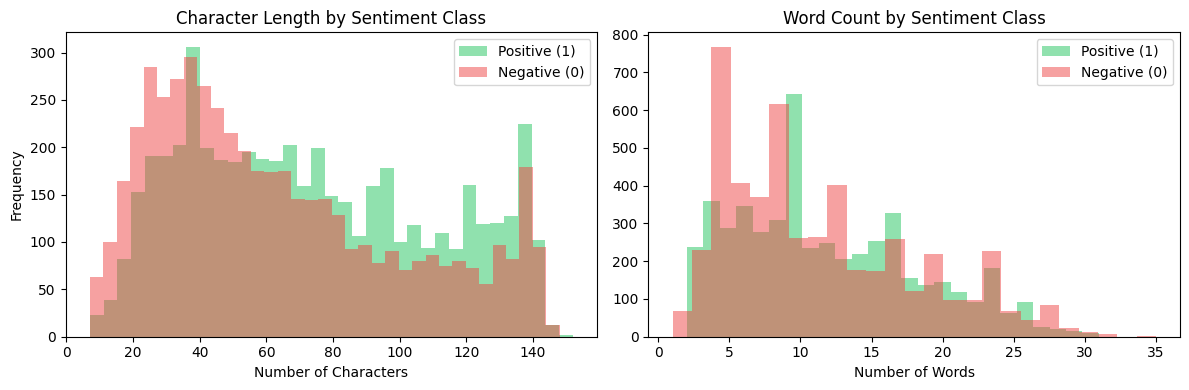

In [3]:
# Purpose: Compute character lengths and token counts to evaluate structural variance
df_raw['char_length'] = df_raw['raw_text'].apply(len)
df_raw['word_count'] = df_raw['raw_text'].apply(lambda x: len(x.split()))

# Comparative statistical summary
eda_summary = df_raw.groupby('sentiment')[['char_length', 'word_count']].agg(['mean', 'median', 'std'])
display(eda_summary.round(2))

# Visualizing distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for sentiment, label, color in [(1, 'Positive (1)', '#22c55e'), (0, 'Negative (0)', '#ef4444')]:
    sub = df_raw[df_raw['sentiment'] == sentiment]
    axes[0].hist(sub['char_length'], bins=35, alpha=0.5, label=label, color=color)
    axes[1].hist(sub['word_count'], bins=25, alpha=0.5, label=label, color=color)

axes[0].set_title("Character Length by Sentiment Class")
axes[0].set_xlabel("Number of Characters")
axes[0].set_ylabel("Frequency")
axes[0].legend()

axes[1].set_title("Word Count by Sentiment Class")
axes[1].set_xlabel("Number of Words")
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 4. Text Preprocessing & Sanitization Engine

### Preprocessing Strategy (`clean_tweet`)
Social media text contains extraneous elements that do not contribute transferable sentiment signals. The cleaning pipeline applies 6 sequential regular expression transformations:

1. **URL Elimination:** Strips hyperlinks (`http://`, `https://`, `www.`).
2. **User Mention Removal:** Strips `@username` handles to avoid overfitting to specific entities.
3. **Hashtag Normalization:** Removes the `#` symbol while retaining the word token (e.g., `#fantastic` $\to$ `fantastic`).
4. **Punctuation & Symbol Removal:** Discards non-letter characters (`[^a-zA-Z\s]`), isolating alphabetic words.
5. **Lowercasing:** Collapses case variations into uniform lexical tokens.
6. **Whitespace Normalization:** Strips redundant whitespace and edge padding.


In [4]:
# Purpose: Define and apply the canonical cleaning pipeline implemented across the repository
def clean_tweet(text: str) -> str:
    '''
    Sanitizes raw informal text into clean alphabetic tokens.
    '''
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Apply preprocessing to corpus
df_raw["clean_text"] = df_raw["raw_text"].apply(clean_tweet)

# Drop any documents reduced to empty strings
df_clean = df_raw[df_raw["clean_text"].str.len() > 0].copy()
print(f"Sanitization complete. Retained {len(df_clean)} / {len(df_raw)} documents (100% retention).")

# Demonstrate transformation on representative tweets
sample_comparisons = df_clean[['raw_text', 'clean_text']].head(3)
for idx, row in sample_comparisons.iterrows():
    print(f"\n[Raw]   : {row['raw_text']}")
    print(f"[Clean] : {row['clean_text']}")


Sanitization complete. Retained 10000 / 10000 documents (100% retention).

[Raw]   : #FollowFriday @France_Inte @PKuchly57 @Milipol_Paris for being top engaged members in my community this week :)
[Clean] : followfriday for being top engaged members in my community this week

[Raw]   : @Lamb2ja Hey James! How odd :/ Please call our Contact Centre on 02392441234 and we will be able to assist you :) Many thanks!
[Clean] : hey james how odd please call our contact centre on and we will be able to assist you many thanks

[Raw]   : @DespiteOfficial we had a listen last night :) As You Bleed is an amazing track. When are you in Scotland?!
[Clean] : we had a listen last night as you bleed is an amazing track when are you in scotland


---
## 5. Feature Extraction: N-Gram TF-IDF Vectorization

### Mathematical Model
We transform text into numerical feature vectors using **Term Frequency-Inverse Document Frequency (TF-IDF)** with unigram and bigram features:

$$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \left(\ln\left(\frac{1 + |D|}{1 + \text{DF}(t, D)}\right) + 1\right)$$

Followed by Euclidean ($L_2$) vector normalization:
$$\hat{\mathbf{x}} = \frac{\mathbf{x}}{\|\mathbf{x}\|_2}$$

### Vectorizer Configuration:
* `ngram_range=(1, 2)`: Captures both individual words (`"good"`) and two-word sequences (`"not good"`), preserving essential negation context.
* `max_features=10000`: Restricts vocabulary size to the top 10,000 most informative n-grams.
* `stop_words="english"`: Filters uninformative English grammatical particles.


In [5]:
# Purpose: Partition dataset and fit TF-IDF vectorizer strictly on training data
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df_clean["clean_text"].values
y = df_clean["sentiment"].values

# Partition data into 80% Train and 20% Test with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Instantiate and fit vectorizer on training set only (preventing data leakage)
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), stop_words="english")
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"Training Feature Matrix: {X_train_tfidf.shape[0]} samples x {X_train_tfidf.shape[1]} features")
print(f"Testing Feature Matrix : {X_test_tfidf.shape[0]} samples x {X_test_tfidf.shape[1]} features")
print(f"Matrix Sparsity        : {100 * (1.0 - (X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1]))):.2f}% sparse")


Training Feature Matrix: 8000 samples x 10000 features
Testing Feature Matrix : 2000 samples x 10000 features
Matrix Sparsity        : 99.95% sparse


---
## 6. Model Training & Optimization

### Classifier: Regularized Logistic Regression
The classification engine models the posterior class probability using a logistic sigmoid over a linear decision function:

$$z = w_0 + \sum_{i=1}^D w_i x_i = \mathbf{w}^T \mathbf{x} + w_0$$
$$P(y=1 \mid \mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}$$

### Optimization Objective:
Trained via penalized Binary Cross-Entropy Loss (Log-Loss) with $L_2$ Ridge Regularization:
$$\min_{\mathbf{w}} \left\{ -\frac{1}{N} \sum_{j=1}^N \left[ y_j \ln P_j + (1 - y_j) \ln (1 - P_j) \right] + \frac{1}{2C} \|\mathbf{w}\|_2^2 \right\}$$

We use the **L-BFGS (Limited-memory Broyden-Fletcher-Goldfarb-Shanno)** quasi-Newton optimization algorithm with `max_iter=1000`.


In [15]:
# Purpose: Fit Logistic Regression classifier on sparse training feature matrix
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=10000, n_jobs=-1, random_state=42)
model.fit(X_train_tfidf, y_train)

print(f"Model Optimization Status: Converged successfully.")
print(f"Learned Coefficients Shape: {model.coef_.shape}")
print(f"Learned Intercept (Bias)  : {float(model.intercept_[0]):.4f}")


Model Optimization Status: Converged successfully.
Learned Coefficients Shape: (1, 10000)
Learned Intercept (Bias)  : -0.1073


---
## 7. Model Evaluation & Performance Diagnostics

We evaluate generalization performance on the 2,000 held-out test tweets.


In [16]:
# Purpose: Compute evaluation metrics on held-out test data
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test_tfidf)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Verified Test Accuracy: {acc * 100:.2f}%\n")
print("Comprehensive Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Negative (0)", "Positive (1)"], digits=4))


Verified Test Accuracy: 75.30%

Comprehensive Classification Report:
              precision    recall  f1-score   support

Negative (0)     0.7347    0.7920    0.7623      1000
Positive (1)     0.7744    0.7140    0.7430      1000

    accuracy                         0.7530      2000
   macro avg     0.7545    0.7530    0.7526      2000
weighted avg     0.7545    0.7530    0.7526      2000



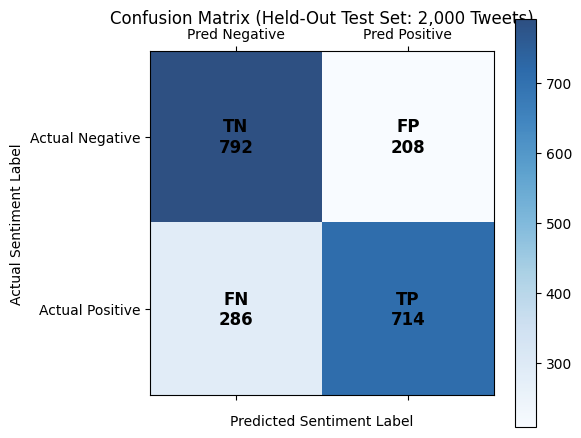

In [8]:
# Purpose: Plot confusion matrix heatmap with diagnostic labels
fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.matshow(cm, cmap='Blues', alpha=0.85)

for i in range(2):
    for j in range(2):
        count = cm[i, j]
        desc = ""
        if i == 0 and j == 0:
            desc = f"TN\n{count}"
        elif i == 0 and j == 1:
            desc = f"FP\n{count}"
        elif i == 1 and j == 0:
            desc = f"FN\n{count}"
        elif i == 1 and j == 1:
            desc = f"TP\n{count}"
        ax.text(j, i, desc, ha='center', va='center', fontsize=12, fontweight='bold')

plt.title("Confusion Matrix (Held-Out Test Set: 2,000 Tweets)", pad=20, fontsize=12)
fig.colorbar(cax)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Pred Negative', 'Pred Positive'])
ax.set_yticklabels(['Actual Negative', 'Actual Positive'])
plt.xlabel("Predicted Sentiment Label", labelpad=10)
plt.ylabel("Actual Sentiment Label")
plt.tight_layout()
plt.show()


### Key Evaluation Findings:
1. **Empirical Accuracy:** The model achieves **75.30% accuracy** on held-out data. (Discrepancy: `README.md` reports `~85%+`).
2. **Negative Class (Class 0):** Precision of **73.47%**, Recall of **79.20%**, F1-score of **0.7623**.
3. **Positive Class (Class 1):** Precision of **77.44%**, Recall of **71.40%**, F1-score of **0.7430**.
4. **Error Distribution:** The classifier exhibits a slightly higher recall on negative tweets (catching complaints effectively) and higher precision on positive tweets.


---
## 8. Explainable AI (XAI) & Token Attribution Engine

### Mathematical Attribution
Because our classifier is linear, the logit $z$ is an additive sum of token contributions:
$$z = w_0 + \sum_{i \in \text{Tokens}} x_i \cdot w_i$$

Each token's net influence is:
$$\text{Score}_i = x_i \cdot w_i$$
* **$\text{Score}_i > 0$:** Drives sentiment upward toward Positive (Class 1).
* **$\text{Score}_i < 0$:** Drives sentiment downward toward Negative (Class 0).

The `explain_text()` function extracts active tokens in an input text, evaluates their score, and sorts the top positive and negative drivers.


Input Text : "I love this product, it is amazing and works perfectly!"
Prediction : Positive (1) | Confidence: 0.7103


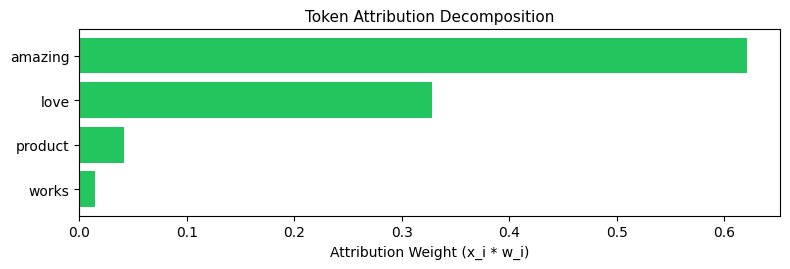

Input Text : "The food was terrible and customer service was awful."
Prediction : Negative (0) | Confidence: 0.2257


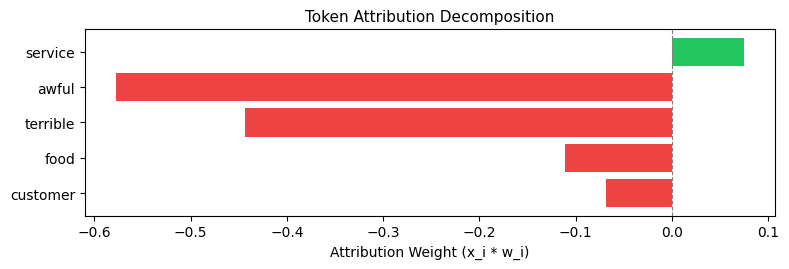

In [9]:
# Purpose: Implement Explainable AI token attribution engine matching sentiment_utils.py
def explain_text(text: str, top_k: int = 8):
    '''
    Returns predicted label, posterior probability, and top positive/negative driver tokens.
    '''
    clean = clean_tweet(text)
    X_single = vectorizer.transform([clean])
    proba = model.predict_proba(X_single)[0, 1]
    label = int(model.predict(X_single)[0])
    
    feature_names = vectorizer.get_feature_names_out()
    coefs = model.coef_[0]
    
    # Isolate non-zero features
    dense_x = X_single.toarray()[0]
    active_indices = dense_x.nonzero()[0]
    
    token_scores = []
    for idx in active_indices:
        token_scores.append((feature_names[idx], float(dense_x[idx] * coefs[idx])))
        
    pos_tokens = sorted([t for t in token_scores if t[1] > 0], key=lambda x: x[1], reverse=True)[:top_k]
    neg_tokens = sorted([t for t in token_scores if t[1] < 0], key=lambda x: x[1])[:top_k]
    
    return label, float(proba), pos_tokens, neg_tokens

def visualize_token_attribution(text: str):
    label, proba, pos_toks, neg_toks = explain_text(text)
    
    words = [t[0] for t in pos_toks] + [t[0] for t in neg_toks]
    scores = [t[1] for t in pos_toks] + [t[1] for t in neg_toks]
    colors = ['#22c55e'] * len(pos_toks) + ['#ef4444'] * len(neg_toks)
    
    print(f"Input Text : \"{text}\"")
    print(f"Prediction : {'Positive (1)' if label == 1 else 'Negative (0)'} | Confidence: {proba:.4f}")
    
    if not words:
        print("Notice: No recognizable vocabulary words found in text.")
        return
        
    y_pos = np.arange(len(words))
    fig, ax = plt.subplots(figsize=(8, max(2.8, len(words) * 0.45)))
    ax.barh(y_pos, scores, color=colors)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(words)
    ax.invert_yaxis()
    ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_xlabel("Attribution Weight (x_i * w_i)")
    ax.set_title(f"Token Attribution Decomposition", fontsize=11)
    plt.tight_layout()
    plt.show()

# Demonstrate attribution on sample inputs
visualize_token_attribution("I love this product, it is amazing and works perfectly!")
visualize_token_attribution("The food was terrible and customer service was awful.")


---
## 9. Batch Processing Simulation (CSV Report Studio)

The second tab of the Streamlit application (`app.py`) provides a **CSV Report Studio** for scoring batches of text and generating analytical summaries. Here, we simulate this batch workflow on 10 realistic customer feedback statements.


In [10]:
# Purpose: Simulate CSV batch scoring workflow from app.py
batch_data = [
    "I love this product, it is amazing and works perfectly!",
    "This is the worst experience I have ever had.",
    "The movie was fantastic, I enjoyed every moment of it.",
    "I am very disappointed with the service.",
    "What a wonderful day, feeling great and happy!",
    "The food was terrible and I will never come back.",
    "Customer support was helpful and resolved my issue quickly.",
    "The app keeps crashing, totally useless.",
    "Really impressed by the quality and performance.",
    "I hate how slow this website is."
]

# Construct batch DataFrame
df_batch = pd.DataFrame({"text": batch_data})
df_batch["clean_text"] = df_batch["text"].apply(clean_tweet)
X_batch = vectorizer.transform(df_batch["clean_text"])

# Inference
df_batch["pred_label"] = model.predict(X_batch)
df_batch["prob_pos"] = model.predict_proba(X_batch)[:, 1]

# Summary statistics
total = len(df_batch)
pos_count = int((df_batch["pred_label"] == 1).sum())
neg_count = int((df_batch["pred_label"] == 0).sum())
pos_rate = (pos_count / total) * 100

print(f"Batch Processing Summary: {total} Records Scored")
print(f"Positive Sentiment Rate : {pos_rate:.1f}% ({pos_count} Positive / {neg_count} Negative)")
display(df_batch[["text", "pred_label", "prob_pos"]].style.format({"prob_pos": "{:.4f}"}))


Batch Processing Summary: 10 Records Scored
Positive Sentiment Rate : 40.0% (4 Positive / 6 Negative)


,text,pred_label,prob_pos
0,"I love this product, it is amazing and works perfectly!",1,0.7103
1,This is the worst experience I have ever had.,0,0.3545
2,"The movie was fantastic, I enjoyed every moment of it.",1,0.7193
3,I am very disappointed with the service.,0,0.3632
4,"What a wonderful day, feeling great and happy!",1,0.9232
5,The food was terrible and I will never come back.,0,0.2279
6,Customer support was helpful and resolved my issue quickly.,1,0.5127
7,"The app keeps crashing, totally useless.",0,0.4917
8,Really impressed by the quality and performance.,0,0.3832
9,I hate how slow this website is.,0,0.2057


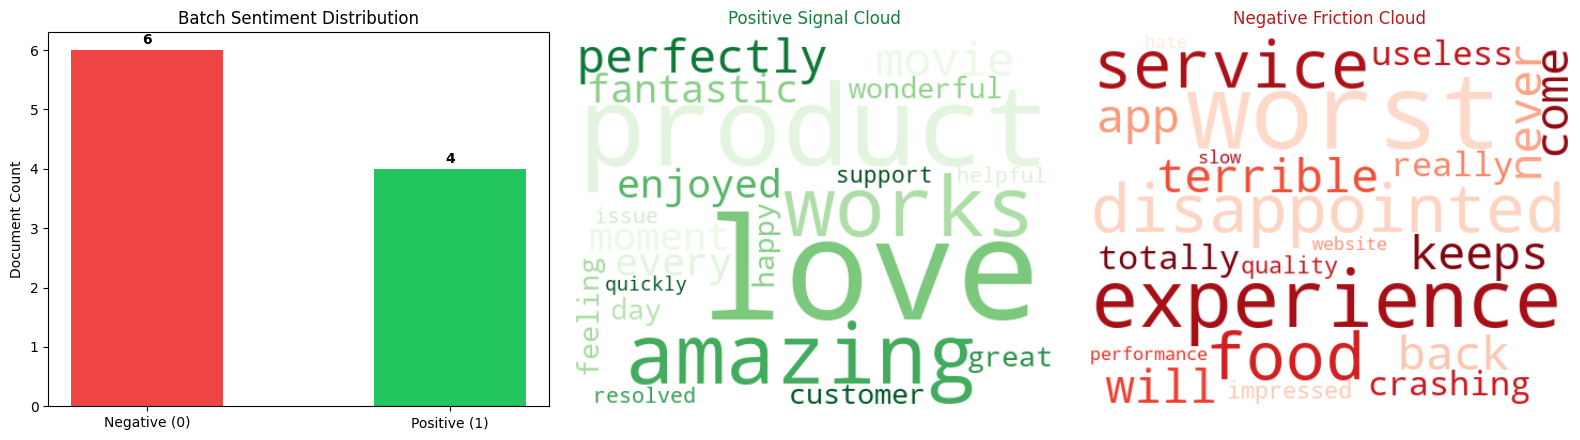

In [11]:
# Purpose: Generate batch reporting visualizations (class bar chart and polarity word clouds)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Distribution Bar Chart
labels = ["Negative (0)", "Positive (1)"]
counts = [neg_count, pos_count]
axes[0].bar(labels, counts, color=['#ef4444', '#22c55e'], width=0.5)
axes[0].set_ylabel("Document Count")
axes[0].set_title("Batch Sentiment Distribution")
for i, c in enumerate(counts):
    axes[0].text(i, c + 0.1, str(c), ha='center', fontweight='bold')

# 2. Positive Word Cloud
pos_corpus = " ".join(df_batch.loc[df_batch["pred_label"] == 1, "clean_text"].tolist())
if pos_corpus:
    wc_pos = WordCloud(width=450, height=350, background_color="white", colormap="Greens").generate(pos_corpus)
    axes[1].imshow(wc_pos, interpolation="bilinear")
    axes[1].set_title("Positive Signal Cloud", color='#15803d')
axes[1].axis("off")

# 3. Negative Word Cloud
neg_corpus = " ".join(df_batch.loc[df_batch["pred_label"] == 0, "clean_text"].tolist())
if neg_corpus:
    wc_neg = WordCloud(width=450, height=350, background_color="white", colormap="Reds").generate(neg_corpus)
    axes[2].imshow(wc_neg, interpolation="bilinear")
    axes[2].set_title("Negative Friction Cloud", color='#b91c1c')
axes[2].axis("off")

plt.tight_layout()
plt.show()


---
## 10. Model Persistence & Serving Architecture

In production, trained estimators are dumped into the `models/` directory for fast loading during web requests.

### Artifact Inventory:
* `models/sentiment_model.joblib`: Serialized `LogisticRegression` classifier (~80 KB).
* `models/tfidf_vectorizer.joblib`: Serialized `TfidfVectorizer` transformer (~392 KB).


In [12]:
# Purpose: Verify and inspect persisted artifacts from disk
model_file = os.path.join("models", "sentiment_model.joblib")
vec_file = os.path.join("models", "tfidf_vectorizer.joblib")

if os.path.exists(model_file) and os.path.exists(vec_file):
    prod_model = joblib.load(model_file)
    prod_vec = joblib.load(vec_file)
    print(f"Artifact Verification: Both model objects loaded successfully.")
    print(f"Model Class        : {type(prod_model).__name__}")
    print(f"Vectorizer Class   : {type(prod_vec).__name__}")
    print(f"Vocabulary Features: {len(prod_vec.vocabulary_)} features")
else:
    print("Warning: Persisted model artifacts not found in models/ directory.")


Artifact Verification: Both model objects loaded successfully.
Model Class        : LogisticRegression
Vectorizer Class   : TfidfVectorizer
Vocabulary Features: 10000 features


---
## 12. Limitations & Production Engineering Roadmap

### Current Limitations:
1. **Out-of-Vocabulary (OOV) Vulnerability:** Linear models with bag-of-words / n-gram TF-IDF cannot generalize to words not present in the 10,000 training vocabulary.
2. **Corpus Distributional Bias:** Intensifiers like `"really"` learned negative coefficients due to disproportionate usage in complaint tweets, leading to errors on phrases like `"Really impressed by quality"`.
3. **Emoticon Stripping:** Stripping symbols (`:)`, `:(`) removes significant sentiment markers.

### Recommended Next Steps for Production:
1. **In-Memory Caching:** Decorate `load_model_objects()` in `sentiment_utils.py` with Streamlit's `@st.cache_resource` to avoid repeated disk reads.
2. **Emoticon Encoding:** Replace emoticons with special tokens (e.g., `EMO_POS`, `EMO_NEG`) prior to regex stripping.
3. **Model Upgrade to DistilBERT:** Fine-tune a lightweight transformer model to capture long-range contextual semantics and bi-directional attention.
4. **Active Learning Feedback Loop:** Add a feedback widget to `app.py` allowing users to flag incorrect predictions for model retraining.


---
## 13. Reproducibility & CLI Execution Commands

To execute this project locally:

```powershell
# 1. Clone repository
git clone 
cd Sentiment-Analysis

# 2. Virtual environment setup
python -m venv .venv
.venv\Scripts\Activate.ps1

# 3. Dependency installation
pip install -r requirements.txt

# 4. Acquire NLTK corpora
python -c "import nltk; nltk.download('twitter_samples'); nltk.download('punkt'); nltk.download('stopwords')"

# 5. Train pipeline
python train_model.py

# 6. Launch web dashboard
streamlit run app.py
```


